# What message passing and Monte Carlo call the giant component

**Internship at CoMuNe Lab** · Riccardo Corte

In notebook 03 (section 3) and notebook 04 (section 2), with betweenness screening and `f = 0.1`, `S ≈ 0.09-0.10` already at `φ = 0`, on all the three
networks: every non-screened node has failed, and a giant component is still there. This notebook checks that the
result is correct and shows which nodes survive.

The goal here is to check whether the nodes with the highest betweenness are actually linked to each other or if that result is an artefact of imprecise coding.

Structure: 0. setup and networks; 1. checks at `φ = 0`; 2. who survives: drawings; 3. what the two
methods call the giant component, with toy networks (3.1-3.5). The functions are imported from `mp.py`.

## 0. Setup

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

from mp import (message_passing, mc_1run, curve_mc, scarto_quadratico_medio, matrice_G, lambda_max,
                estrai_protetti, phi_ibrido, phi_efficace, matrice_M, lambda_zero, soglia_bisezione,
                budget_critico, lcc_protetti)

rng = np.random.default_rng(0)


### 0.1 Networks

The three test networks of notebook 03, section 1 (same parameters and seeds), and the
positions used in the drawings.

In [2]:
# --- parameters ---
N_big = 1000        # number of nodes of each graph
n_blocchi = 4       # communities of the block model, N_big / n_blocchi nodes each
k_dentro = 2.8      # mean number of links of a node inside its own community
k_fuori = 0.2       # mean number of links of a node towards the other communities
k_er = 3            # mean degree of the Erdos-Renyi graph
m_ba = 3            # links brought by each new node in the Barabasi-Albert graph

# link probabilities of the block model: with n nodes per community, a node has n - 1 possible
# partners inside and N_big - n outside, so p = (mean number of links) / (possible partners)
n_com = N_big // n_blocchi
p_dentro = k_dentro / (n_com - 1)
p_fuori = k_fuori / (N_big - n_com)

# --- the three graphs ---
grafi = {
    "communities": nx.stochastic_block_model(
        [N_big // n_blocchi] * n_blocchi,
        [[p_dentro if a == b else p_fuori for b in range(n_blocchi)] for a in range(n_blocchi)],
        seed=1),
    "Erdos-Renyi": nx.gnp_random_graph(N_big, k_er / (N_big - 1), seed=1),
    "Barabasi-Albert": nx.barabasi_albert_graph(N_big, m_ba, seed=1),
}

# --- check: what we have built ---
for nome, g in grafi.items():
    gradi = [d for _, d in g.degree]
    lcc = max(nx.connected_components(g), key=len)
    print(nome)
    print("  nodes:", g.number_of_nodes(), " links:", g.number_of_edges())
    print("  mean degree:", np.mean(gradi), " min:", min(gradi), " max:", max(gradi))
    print("  connected:", nx.is_connected(g), " LCC/N with no removal:", len(lcc) / N_big)

# links between different communities (the block of each node is in the attribute "block")
g = grafi["communities"]
tra = sum(1 for u, v in g.edges() if g.nodes[u]["block"] != g.nodes[v]["block"])
print("communities: links between communities", tra, "out of", g.number_of_edges())


communities
  nodes: 1000  links: 1529
  mean degree: 3.058  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.943
Erdos-Renyi
  nodes: 1000  links: 1486
  mean degree: 2.972  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.934
Barabasi-Albert
  nodes: 1000  links: 2991
  mean degree: 5.982  min: 1  max: 91
  connected: True  LCC/N with no removal: 1.0
communities: links between communities 94 out of 1529


In [3]:
# node positions for the drawings: slow to compute (about 30 s), to be run only once
posizioni = {nome: nx.spring_layout(g, seed=1) for nome, g in grafi.items()}


## 1. Checks at φ = 0

For each network and `f = 0, 0.01, 0.05, 0.10`, betweenness screening, `φ = 0`:

1. **S against f**: `S` cannot exceed `f` unless non-screened nodes survive, and at `φ = 0` none can.
2. **Largest component of the screened nodes alone** (subgraph induced by the screened nodes), against `S` from Monte
   Carlo and from message passing. At `φ = 0` there is no randomness left, so one Monte Carlo run is enough.
3. **Links among the screened nodes**, and how many screened nodes have at least one screened neighbour.
4. **Random baseline**: the same `f` drawn at random, 10 draws, largest component of the screened nodes (mean and
   maximum). If nothing survives there, the effect is due to betweenness.

`f = 0` is the case with no screened node: `S = 0` by construction.

In [4]:
rng_6 = np.random.default_rng(21)      # own generator: the results do not depend on the cells run before
frazioni_6 = [0.0, 0.01, 0.05, 0.10]
betw_6 = {nome: nx.betweenness_centrality(g) for nome, g in grafi.items()}



In [5]:
righe = []
for nome, g in grafi.items():
    for f in frazioni_6:
        protetti = estrai_protetti(g, f, "betweenness", rng_6, betw_6[nome])
        phi_n = phi_ibrido(g, protetti, 0.0)
        S_mc = mc_1run(g, phi_n, rng_6) if f > 0 else 0.0
        S_mp = message_passing(g, phi_n)[0] if f > 0 else 0.0
        H = g.subgraph(protetti)
        lcc_rand = [lcc_protetti(g, estrai_protetti(g, f, "random", rng_6)) for _ in range(10)]
        righe.append({"network": nome, "f": f, "S MC": S_mc, "S MP": S_mp,
                      "LCC screened": lcc_protetti(g, protetti),
                      "links among screened": H.number_of_edges(),
                      "screened with a screened neighbour": sum(1 for n in protetti if H.degree[n] > 0),
                      "LCC random mean": np.mean(lcc_rand), "LCC random max": np.max(lcc_rand)})
controlli_6 = pd.DataFrame(righe)
controlli_6.round(3)


,network,f,S MC,S MP,LCC screened,links among screened,screened with a screened neighbour,LCC random mean,LCC random max
0,communities,0.00,0.000,0.000,0.000,0,0,0.000,0.000
1,communities,0.01,0.003,0.000,0.003,4,7,0.001,0.002
2,communities,0.05,0.019,0.000,0.019,36,45,0.002,0.003
3,communities,0.10,0.095,0.095,0.095,105,97,0.003,0.004
4,Erdos-Renyi,0.00,0.000,0.000,0.000,0,0,0.000,0.000
5,Erdos-Renyi,0.01,0.002,0.000,0.002,4,8,0.001,0.002
6,Erdos-Renyi,0.05,0.019,0.000,0.019,38,45,0.002,0.003
7,Erdos-Renyi,0.10,0.089,0.089,0.089,94,91,0.005,0.008
8,Barabasi-Albert,0.00,0.000,0.000,0.000,0,0,0.000,0.000
9,Barabasi-Albert,0.01,0.010,0.010,0.010,21,10,0.001,0.002


#### Comment on section 1

- `S ≤ f` in every case: at `φ = 0` only screened nodes survive. With `f = 0`, `S = 0`.
- Monte Carlo `S` always equals the largest component of the screened nodes alone. Message passing `S` equals it only
  at `f = 0.1`, and on Barabási-Albert at every `f`: the two methods call "giant component" two different things
  (section 3).
- At `f = 0.1` the screened nodes percolate alone: `f = 0.1` is above the critical budget of betweenness (`f* = 0.079`
  on communities and Erdős-Rényi, notebook 04, section 1.2), so `λ(0) ≥ 1` and their subgraph contains cycles (a forest would give
  `λ(0) = 0`). The 100 screened nodes share 105 links on communities and 94 on Erdős-Rényi.
- At `f = 0.01` and `0.05` on communities and Erdős-Rényi message passing gives `S = 0` while the largest component of
  the screened nodes is 0.002-0.019. These components are trees (`λ(0) = 0`), and on a tree message passing gives
  `s_i = 0` whatever its size (section 3).
- Random baseline with the same `f`: the largest component of the screened nodes is at most 0.004-0.021. The effect is
  due to the choice by betweenness.

## 2. Who survives: drawings

Fixed layout of the original network (the positions of section 0.1). Removed nodes in light grey; surviving nodes and
their links in orange, darker for the largest component; screened nodes with a black border, so that they can be told
apart from non-screened nodes that survive by being linked to a screened one.

1. `φ = 0`: rows betweenness `f = 0.05`, betweenness `f = 0.1`, random `f = 0.1` (for comparison).
2. `φ = 0.1`, betweenness `f = 0.1`: one Monte Carlo run, where also non-screened nodes survive.

In [6]:
def disegna(ax, g, pos, protetti, phi, titolo, rng):
    """One realisation at phi: removed nodes light grey, surviving nodes orange (the largest component darker),
    screened nodes with a black border."""
    presenti = set(protetti) | {n for n in g.nodes if n not in protetti and rng.random() < phi}
    H = g.subgraph(presenti)
    lcc = max(nx.connected_components(H), key=len) if len(H) else set()
    rimossi = [n for n in g.nodes if n not in presenti]
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color="#dddddd", width=0.2)
    nx.draw_networkx_nodes(g, pos, nodelist=rimossi, ax=ax, node_size=5, node_color="#d9d9d9")
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#f5b26b", width=0.6)
    nx.draw_networkx_edges(g.subgraph(lcc), pos, ax=ax, edge_color="#e66101", width=1.0)
    for nodi, colore in [([n for n in presenti if n not in lcc], "#f5b26b"), (list(lcc), "#e66101")]:
        bordo = ["black" if n in protetti else colore for n in nodi]
        nx.draw_networkx_nodes(g, pos, nodelist=nodi, ax=ax, node_size=14, node_color=colore,
                               edgecolors=bordo, linewidths=0.8)
    ax.set_title(f"{titolo}\nS = {len(lcc) / g.number_of_nodes():.3f}", fontsize=11)
    ax.axis("off")


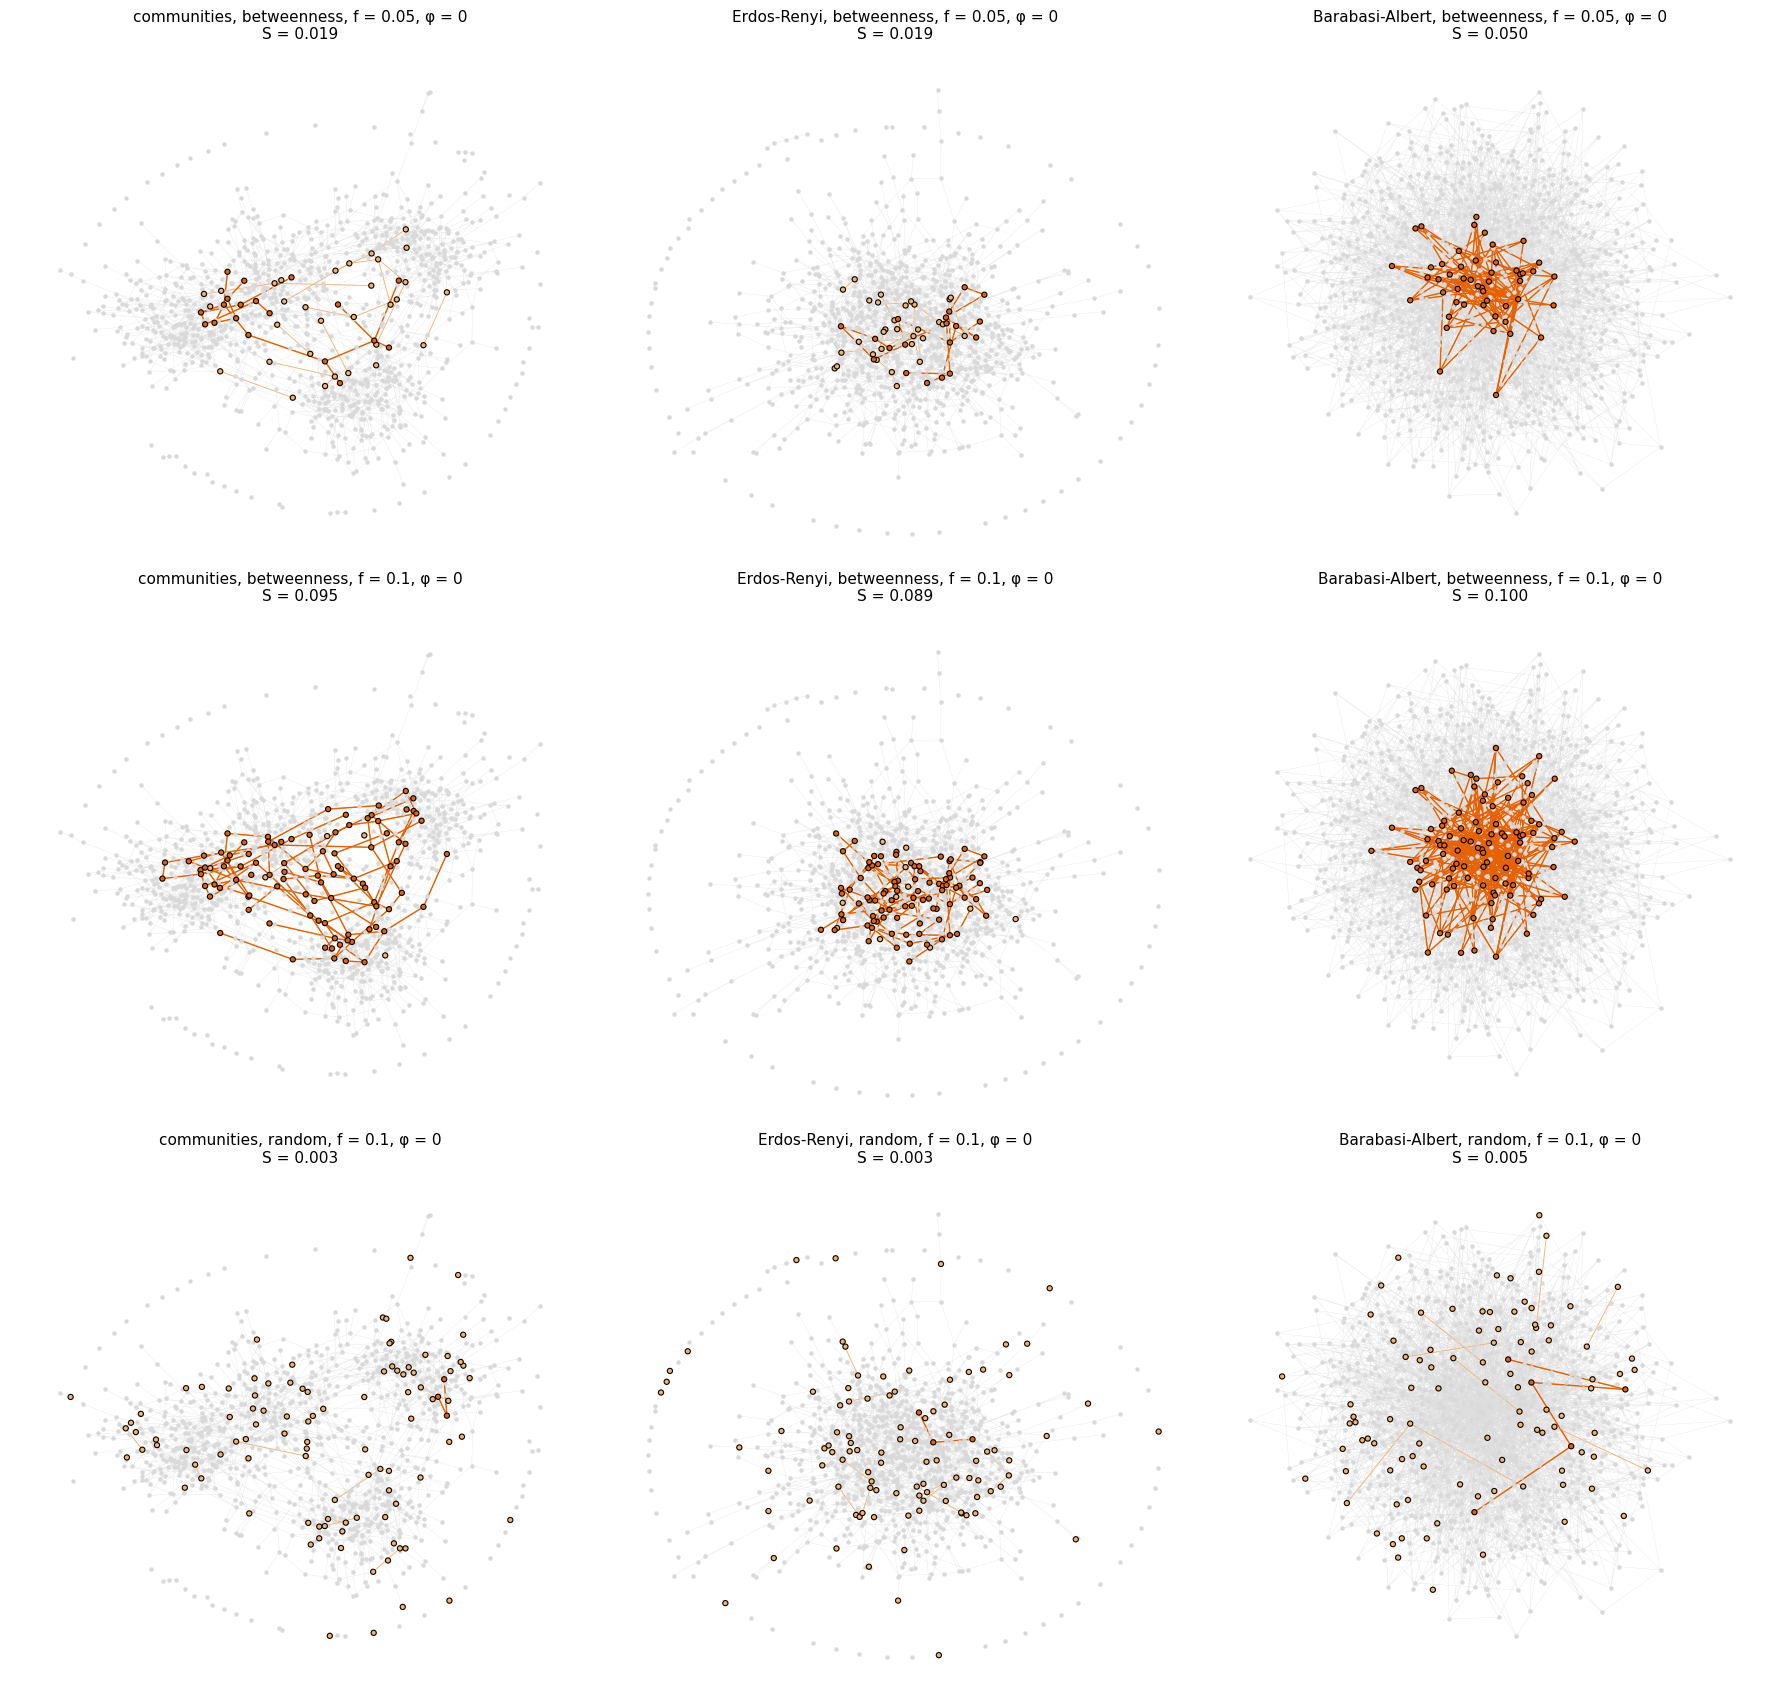

In [7]:
# phi = 0: only the screened nodes survive
casi = [("betweenness", 0.05), ("betweenness", 0.10), ("random", 0.10)]
fig, assi = plt.subplots(len(casi), 3, figsize=(18, 17))
for r, (protocollo, f) in enumerate(casi):
    for c, (nome, g) in enumerate(grafi.items()):
        protetti = estrai_protetti(g, f, protocollo, rng_6, betw_6[nome])
        disegna(assi[r, c], g, posizioni[nome], protetti, 0.0, f"{nome}, {protocollo}, f = {f}, φ = 0", rng_6)
plt.tight_layout()
plt.show()


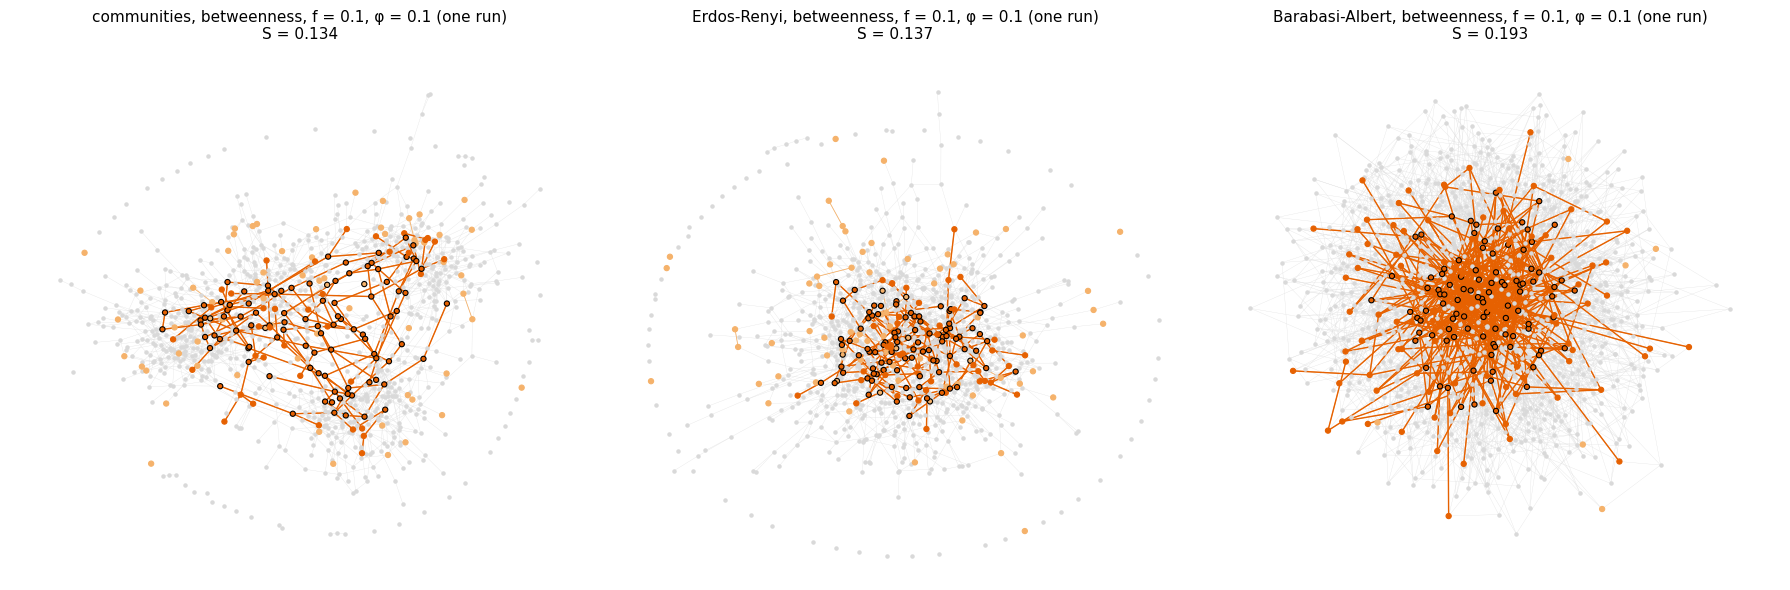

In [8]:
# phi = 0.1: one Monte Carlo run, non-screened nodes can survive too
fig, assi = plt.subplots(1, 3, figsize=(18, 6))
for c, (nome, g) in enumerate(grafi.items()):
    protetti = estrai_protetti(g, 0.10, "betweenness", rng_6, betw_6[nome])
    disegna(assi[c], g, posizioni[nome], protetti, 0.10, f"{nome}, betweenness, f = 0.1, φ = 0.1 (one run)", rng_6)
plt.tight_layout()
plt.show()


#### Comment on section 2

With betweenness the screened nodes sit in the core of the network and, on the network with communities, on the paths
between communities, and they are linked to each other: at `f = 0.1` they form one large connected piece. With random
screening the same number of nodes is scattered and almost isolated. At `φ = 0.1` the non-screened nodes that survive
(orange without black border) join the giant component through the screened backbone.

## 3. What the two methods call the giant component

At `φ = 0` only the screened nodes survive, and `S` depends only on the shape of their subgraph. The two methods
measure it in different ways:

- **Monte Carlo** takes the **largest** connected component of the surviving nodes, whatever its shape (`mc_1run`).
- **Message passing** gives each node `s_i`. A message pointing towards a leaf is 0 (empty product), so on a finite tree
  every message becomes 0 and `s_i = 0`. Around a cycle a message reads itself: starting from `t = 1` it stays at 1, so
  `s_i = 1` on the cycle and on the trees attached to it. Message passing counts **every node in a component with at
  least one cycle**, whatever its size.

Toy case: a triangle of 3 screened nodes and a tree of 6 screened nodes, joined through one non-screened node, `φ = 0`.

triangle: 3 nodes, s_i = [1.0]
tree: 6 nodes, s_i = [0.0]
S MP = 0.3 (3 nodes),  S MC = 0.6 (6 nodes)


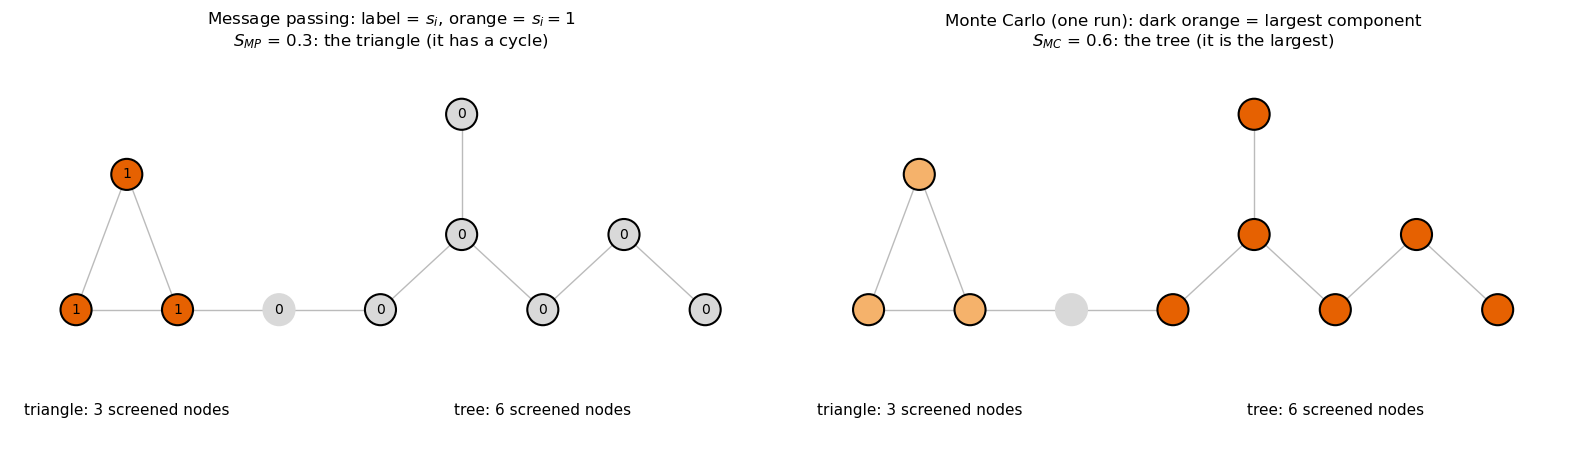

In [9]:
# toy network: triangle 0-1-2 and tree 10-15 (screened), node 20 (not screened) joins them
g_63 = nx.Graph()
g_63.add_edges_from([(0, 1), (1, 2), (2, 0)])                                # triangle
g_63.add_edges_from([(10, 11), (11, 12), (12, 13), (13, 14), (11, 15)])      # tree
g_63.add_edges_from([(2, 20), (20, 10)])                                     # through the non-screened node 20
protetti_63 = [0, 1, 2, 10, 11, 12, 13, 14, 15]
phi_63 = phi_ibrido(g_63, protetti_63, 0.0)

S_mp_63, s_63, t_63, _, _ = message_passing(g_63, phi_63)
S_mc_63 = mc_1run(g_63, phi_63, rng_6)            # at phi = 0 one run is enough: no randomness left
N_63 = g_63.number_of_nodes()

triangolo, albero = [0, 1, 2], [10, 11, 12, 13, 14, 15]
for nome, parte in [("triangle", triangolo), ("tree", albero)]:
    print(f"{nome}: {len(parte)} nodes, s_i = {sorted({round(s_63[n], 3) for n in parte})}")
print(f"S MP = {S_mp_63:.1f} ({S_mp_63 * N_63:.0f} nodes),  S MC = {S_mc_63:.1f} ({S_mc_63 * N_63:.0f} nodes)")

# fixed positions: triangle on the left, tree on the right, node 20 in the middle
pos_63 = {0: (0, 0.6), 1: (-0.5, -0.3), 2: (0.5, -0.3), 20: (1.5, -0.3),
          10: (2.5, -0.3), 11: (3.3, 0.2), 12: (4.1, -0.3), 13: (4.9, 0.2), 14: (5.7, -0.3), 15: (3.3, 1.0)}

fig, assi = plt.subplots(1, 2, figsize=(16, 4.8))

# left: message passing, colour = s_i, label = s_i
ax = assi[0]
nx.draw_networkx_edges(g_63, pos_63, ax=ax, edge_color="#bbbbbb")
nx.draw_networkx_nodes(g_63, pos_63, ax=ax, node_size=500,
                       node_color=["#e66101" if s_63[n] > 0.5 else "#d9d9d9" for n in g_63.nodes],
                       edgecolors=["black" if n in protetti_63 else "#d9d9d9" for n in g_63.nodes], linewidths=1.5)
nx.draw_networkx_labels(g_63, pos_63, ax=ax, labels={n: f"{s_63[n]:.0f}" for n in g_63.nodes}, font_size=10)
ax.set_title(f"Message passing: label = $s_i$, orange = $s_i = 1$\n"
             f"$S_{{MP}}$ = {S_mp_63:.1f}: the triangle (it has a cycle)", fontsize=12)

# right: Monte Carlo, same colours as section 2: removed light grey, largest component dark orange,
# other surviving nodes light orange, screened nodes with a black border
ax = assi[1]
presenti = [n for n in g_63.nodes if phi_63[n] == 1.0]          # at phi = 0 the survivors are the screened nodes
lcc_63 = max(nx.connected_components(g_63.subgraph(presenti)), key=len)
colori = ["#e66101" if n in lcc_63 else "#f5b26b" if n in presenti else "#d9d9d9" for n in g_63.nodes]
nx.draw_networkx_edges(g_63, pos_63, ax=ax, edge_color="#bbbbbb")
nx.draw_networkx_nodes(g_63, pos_63, ax=ax, node_size=500, node_color=colori,
                       edgecolors=["black" if n in protetti_63 else "#d9d9d9" for n in g_63.nodes], linewidths=1.5)
ax.set_title(f"Monte Carlo (one run): dark orange = largest component\n"
             f"$S_{{MC}}$ = {S_mc_63:.1f}: the tree (it is the largest)", fontsize=12)

for ax in assi:
    ax.text(0, -1.0, "triangle: 3 screened nodes", ha="center", fontsize=11)
    ax.text(4.1, -1.0, "tree: 6 screened nodes", ha="center", fontsize=11)
    ax.set_ylim(-1.3, 1.4)
    ax.axis("off")
plt.tight_layout()
plt.show()


On the three test networks: for each `f`, the components of the subgraph of the screened nodes (betweenness), how many
of them contain a cycle, the nodes in those components and the largest component, as fractions of `N`, against
`S MP`.

In [10]:
righe = []
for nome, g in grafi.items():
    for f in frazioni_6[1:]:
        protetti = estrai_protetti(g, f, "betweenness", rng_6, betw_6[nome])
        H = g.subgraph(protetti)
        componenti = list(nx.connected_components(H))
        con_cicli = [c for c in componenti if H.subgraph(c).number_of_edges() >= len(c)]   # a tree has |c| - 1 links
        righe.append({"network": nome, "f": f, "components": len(componenti), "with a cycle": len(con_cicli),
                      "nodes in components with a cycle": sum(len(c) for c in con_cicli) / g.number_of_nodes(),
                      "LCC screened": max(len(c) for c in componenti) / g.number_of_nodes(),
                      "S MP": message_passing(g, phi_ibrido(g, protetti, 0.0))[0]})
pd.DataFrame(righe).round(3)


,network,f,components,with a cycle,nodes in components with a cycle,LCC screened,S MP
0,communities,0.01,6,0,0.000,0.003,0.000
1,communities,0.05,14,0,0.000,0.019,0.000
2,communities,0.10,5,1,0.095,0.095,0.095
3,Erdos-Renyi,0.01,6,0,0.000,0.002,0.000
4,Erdos-Renyi,0.05,12,0,0.000,0.019,0.000
5,Erdos-Renyi,0.10,11,1,0.089,0.089,0.089
6,Barabasi-Albert,0.01,1,1,0.010,0.010,0.010
7,Barabasi-Albert,0.05,1,1,0.050,0.050,0.050
8,Barabasi-Albert,0.10,1,1,0.100,0.100,0.100


#### Comment on section 3

In the toy case message passing gives `s_i = 1` on the triangle and `s_i = 0` on the tree, so `S MP = 0.3`, while Monte
Carlo takes the tree, the largest component, so `S MC = 0.6`. On the test networks `S MP` equals the fraction of
screened nodes in components with a cycle in every case. At most one component has a cycle, so where it exists it is
also the largest one and the two methods agree (`f = 0.1`, and Barabási-Albert); where the largest component is a tree
message passing gives 0 and Monte Carlo does not. We expect the two definitions to coincide on an
infinite, locally tree-like network, where the only infinite component is the giant one and the finite pieces are
trees (not checked here).

#### Where message passing works best

Message passing is exact on trees and works well on large sparse networks that are **locally tree-like**: around
every node, for several steps, the network looks like a tree. Loops are there, but they are long: networks of this
kind "contain loops that grow as log N", and results obtained for tree-like graphs "apply quite well also for loopy
networks, provided the density of loops is not excessively large" (Morone and Makse 2015, arXiv:1506.08326, Methods
sec. II.C, pp. 41-42). The giant component of such a network is full of long loops with trees attached; seen from one
node, the messages leaving in different directions do not meet for many steps, so they are close to independent, which
is the assumption of the equations. Message passing has trouble in two cases:

- **short loops** (triangles): the messages of two neighbours are no longer independent. This is an approximation
  error, and it does not shrink with `N` (notebook 02, section 1.6);
- **small pieces with a cycle** on a finite network: message passing takes them for the giant component. This is a
  difference of definition, the toy case above.

### 3.1 Non-zero φ, (a): an isolated triangle

No screened node, the same `φ` on the three nodes.

In [11]:
triangolo_a = nx.cycle_graph(3)
for phi in [0.5, 0.9, 0.99, 1.0]:
    s_a = message_passing(triangolo_a, phi)[1]
    print(f"φ = {phi}: s_i = {[round(v, 3) for v in s_a.values()]}")


φ = 0.5: s_i = [0.0, 0.0, 0.0]
φ = 0.9: s_i = [0.0, 0.0, 0.0]
φ = 0.99: s_i = [0.0, 0.0, 0.0]
φ = 1.0: s_i = [1.0, 1.0, 1.0]


Going around the cycle the message is multiplied by `φ` at every node: on the triangle `t = φ³ t`, so for `φ < 1` the
only solution is `t = 0`. A single cycle has `λ = 1` exactly (Morone and Makse 2015, p. 38), so `λ(diag(φ)G) = φ < 1`:
the same condition `λ(M) ≥ 1` of the bisection, applied to a small piece. With `φ < 1` a small isolated cycle does not
count any more; only cycles of nodes at `φ = 1` exactly, i.e. screened nodes, are self-sustaining.

### 3.2 Non-zero φ, (b): screened triangle with non-screened neighbours

The toy network of section 3 plus three non-screened neighbours of the triangle (nodes 30, 31, 32), `N = 13`.
Screened: the triangle and the tree. Non-screened: the three neighbours and the bridge 20. Left: message passing at
`φ = 0.5`, label = `s_i`. Centre and right: two Monte Carlo runs at `φ = 0.5`, one where the bridge 20 survives and one
where it fails.

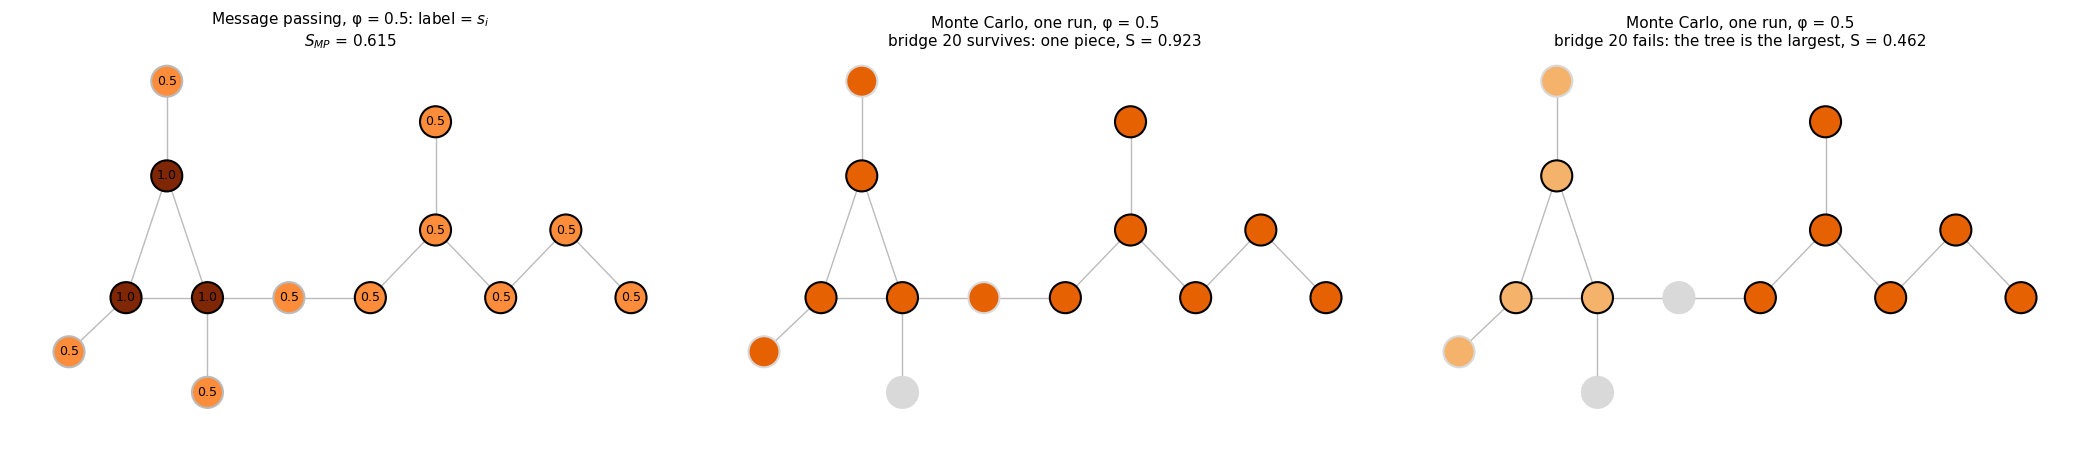

In [12]:
g_b = g_63.copy()
g_b.add_edges_from([(0, 30), (1, 31), (2, 32)])          # non-screened neighbours of the triangle
pos_b = {**pos_63, 30: (0, 1.3), 31: (-1.2, -0.7), 32: (0.5, -1.0)}
N_b = g_b.number_of_nodes()
phi_b = phi_ibrido(g_b, protetti_63, 0.5)
S_mp_b, s_b = message_passing(g_b, phi_b)[:2]


def disegna_63(ax, presenti, titolo):
    """Toy network: removed light grey, largest component of the present nodes dark orange, other present nodes
    light orange, screened nodes with a black border."""
    lcc = max(nx.connected_components(g_b.subgraph(presenti)), key=len)
    colori = ["#e66101" if n in lcc else "#f5b26b" if n in presenti else "#d9d9d9" for n in g_b.nodes]
    nx.draw_networkx_edges(g_b, pos_b, ax=ax, edge_color="#bbbbbb")
    nx.draw_networkx_nodes(g_b, pos_b, ax=ax, node_size=500, node_color=colori, linewidths=1.5,
                           edgecolors=["black" if n in protetti_63 else "#d9d9d9" for n in g_b.nodes])
    ax.set_title(titolo, fontsize=11)
    ax.set_ylim(-1.5, 1.5)
    ax.axis("off")


fig, assi = plt.subplots(1, 3, figsize=(21, 4.8))

# message passing: colour = s_i (white 0, dark orange 1), label = s_i
ax = assi[0]
nx.draw_networkx_edges(g_b, pos_b, ax=ax, edge_color="#bbbbbb")
nx.draw_networkx_nodes(g_b, pos_b, ax=ax, node_size=500, node_color=[s_b[n] for n in g_b.nodes], cmap="Oranges",
                       vmin=0, vmax=1, linewidths=1.5,
                       edgecolors=["black" if n in protetti_63 else "#bbbbbb" for n in g_b.nodes])
nx.draw_networkx_labels(g_b, pos_b, ax=ax, labels={n: f"{s_b[n]:.1f}" for n in g_b.nodes}, font_size=9)
ax.set_title(f"Message passing, φ = 0.5: label = $s_i$\n$S_{{MP}}$ = {S_mp_b:.3f}", fontsize=11)
ax.set_ylim(-1.5, 1.5)
ax.axis("off")

# two Monte Carlo runs: the first draw where the bridge survives, the first where it fails
for ax, vivo in [(assi[1], True), (assi[2], False)]:
    while True:
        presenti = set(protetti_63) | {n for n in g_b.nodes if n not in protetti_63 and rng_6.random() < 0.5}
        if (20 in presenti) == vivo:
            break
    S_run = len(max(nx.connected_components(g_b.subgraph(presenti)), key=len)) / N_b
    stato = "survives: one piece" if vivo else "fails: the tree is the largest"
    disegna_63(ax, presenti, f"Monte Carlo, one run, φ = 0.5\nbridge 20 {stato}, S = {S_run:.3f}")
plt.tight_layout()
plt.show()


How the gap changes with `φ`: message passing against Monte Carlo (5000 runs per point) on the toy network, and the
gap against the formula derived below.

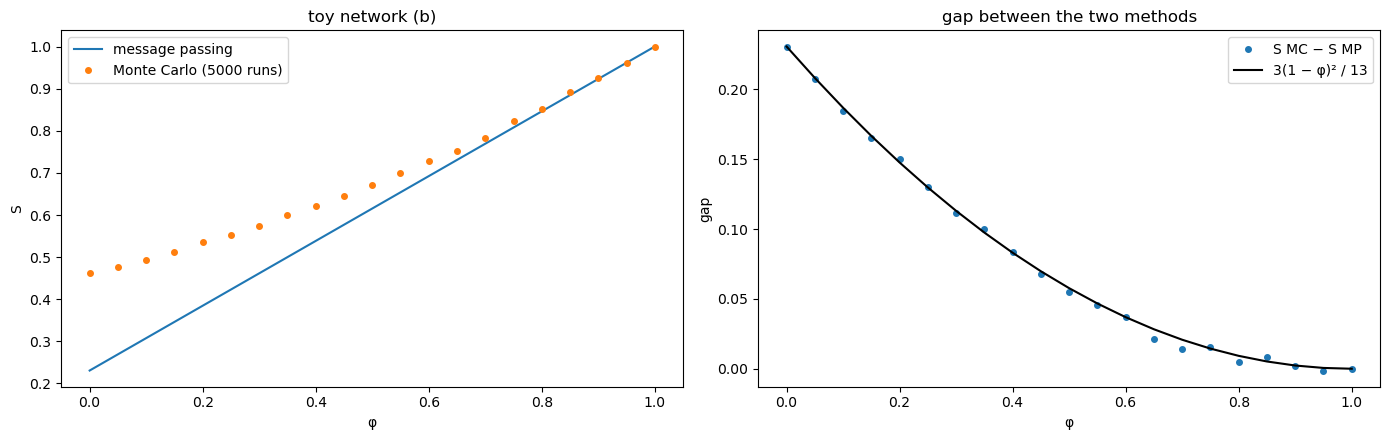

largest |gap − formula|: 0.0067


In [13]:
phis_b = np.linspace(0, 1, 21)
S_mp_curve, S_mc_curve = [], []
for phi in phis_b:
    phi_n = phi_ibrido(g_b, protetti_63, phi)
    S_mp_curve.append(message_passing(g_b, phi_n)[0])
    S_mc_curve.append(np.mean([mc_1run(g_b, phi_n, rng_6) for _ in range(5000)]))
S_mp_curve, S_mc_curve = np.array(S_mp_curve), np.array(S_mc_curve)

fig, assi = plt.subplots(1, 2, figsize=(14, 4.5))
assi[0].plot(phis_b, S_mp_curve, "-", label="message passing")
assi[0].plot(phis_b, S_mc_curve, "o", ms=4, label="Monte Carlo (5000 runs)")
assi[0].set_xlabel("φ"); assi[0].set_ylabel("S"); assi[0].legend(); assi[0].set_title("toy network (b)")
assi[1].plot(phis_b, S_mc_curve - S_mp_curve, "o", ms=4, label="S MC − S MP")
assi[1].plot(phis_b, 3 * (1 - phis_b) ** 2 / N_b, "k-", label="3(1 − φ)² / 13")
assi[1].set_xlabel("φ"); assi[1].set_ylabel("gap"); assi[1].legend(); assi[1].set_title("gap between the two methods")
plt.tight_layout()
plt.show()
print("largest |gap − formula|:", np.max(np.abs(S_mc_curve - S_mp_curve - 3 * (1 - phis_b) ** 2 / N_b)).round(4))


#### Comment on sections 3.1-3.2

**Message passing.** The screened triangle acts as a fake "infinite reservoir": for message passing, a node is in the
giant component if it is connected to the triangle, with the probability of the path. The neighbours 30-32 and the
bridge 20 get `s_i = φ` (they survive with probability `φ`); the tree gets `s_i = φ` too, because it reaches the
triangle only through the bridge. Here message passing makes no approximation: apart from the triangle, whose nodes
are at `φ = 1` and never fail, the network is a tree, so the messages are independent and `S MP` is exactly the
expected number of nodes connected to the triangle: `S MP = (3 + 3φ + φ + 6φ)/13`.

**Monte Carlo.** In every run it takes the largest piece. If the bridge survives (probability `φ`) everything is one
piece, triangle + tree + bridge + surviving neighbours, and both methods count the same nodes. If the bridge fails
(probability `1 − φ`) there are two pieces: the tree (6 nodes) and the triangle with its surviving neighbours
(`3 + B` nodes, `B` ≤ 3 surviving neighbours, on average `3φ`). Monte Carlo takes the tree, message passing counts the
triangle side.

**Why the gap shrinks.** The two methods disagree only when the bridge fails, and then by `6 − (3 + 3φ) = 3 − 3φ`
nodes on average, so

`S MC − S MP = φ * 0 + (1 − φ)(3 − 3φ)/13 = 3(1 − φ)²/13`,

0.231 at `φ = 0`, 0.058 at `φ = 0.5`, 0 at `φ = 1`; the Monte Carlo points follow it within their noise. The gap does
not shrink because message passing becomes more accurate: it is exact at every `φ` for what it computes. It shrinks
because, as `φ` grows, the configurations where "the piece with a cycle" and "the largest piece" are different
become rarer (the bridge fails less often), and in those that remain the two pieces differ by fewer nodes (more
neighbours of the triangle survive). On a real network we expect the same above the threshold: the true giant
component connects to most of the screened clusters, and the two definitions select the same nodes; the difference
should stay large where the screened clusters are cut off from each other, i.e. at low `φ` (not checked on the test
networks).

### 3.3 All the message passing quantities, node by node

For the three toy networks of sections 3-3.2, every quantity of the solver:

- **`φ_i`** (upper label, blue): the probability that node `i` survives;
- **`t_{i→j}`** (arrow from `i` towards `j`, one for each direction of a link): the probability that, following the link
  from `i` to `j`, node **`j`** survives and from `j`, without going back to `i`, the giant component is reached. It is
  about the node the message points to, not the one it leaves from. Red: `t > 0`; grey: `t = 0`;
- **`s_i`** (lower label and node colour): `s_i = φ_i [1 − Π_j (1 − t_{i→j})]`, the probability that `i` survives and
  at least one of its links leads to the giant component.

Black border: screened nodes.

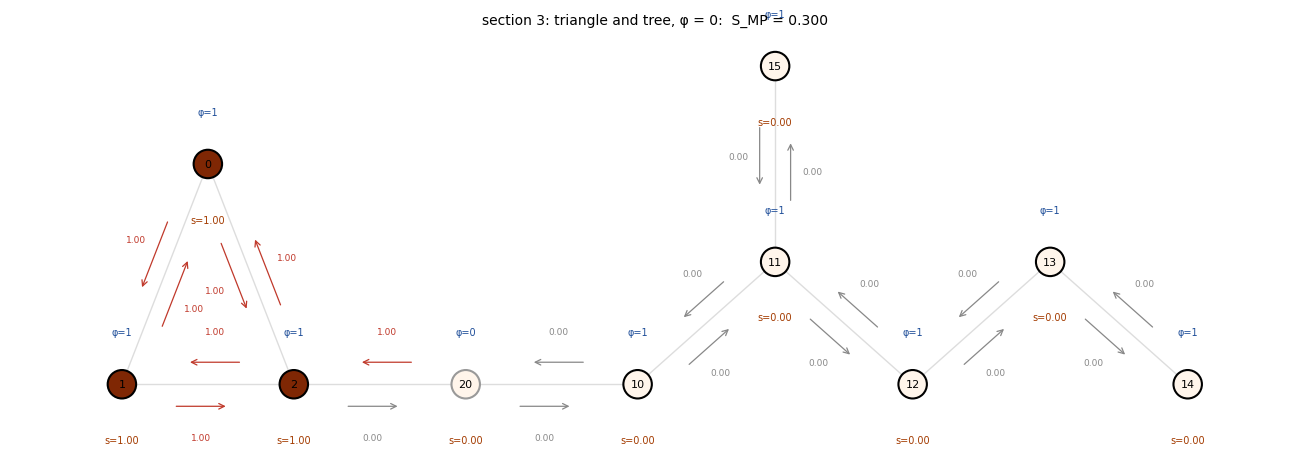

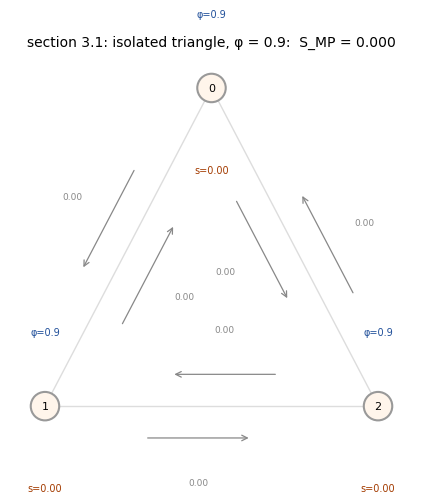

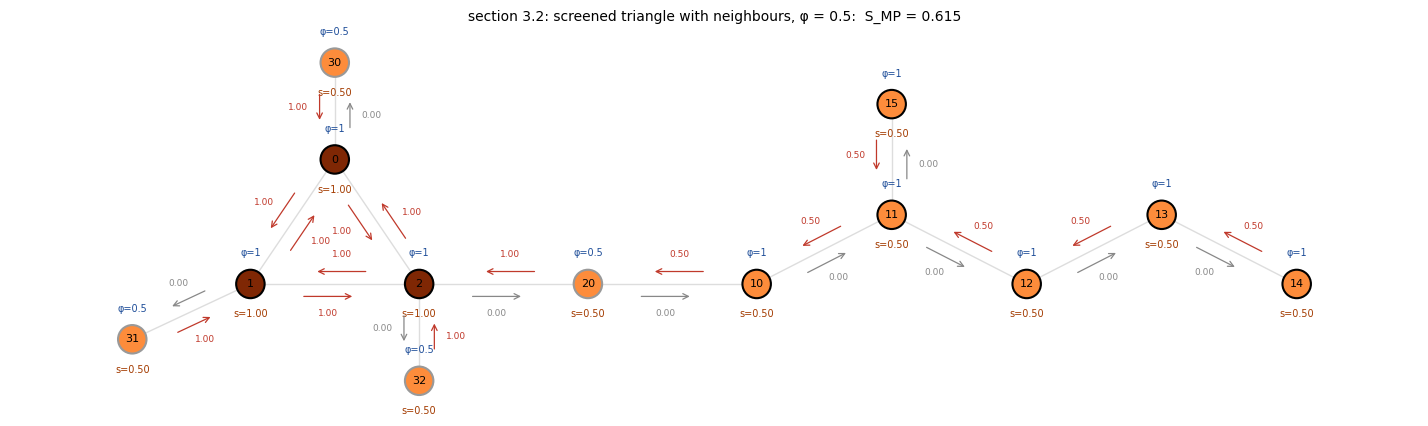

section 3: triangle and tree, φ = 0
      0    1    2    10   11   12   13   14   15   20
φ_i  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  0.0
s_i  1.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0 

section 3.1: isolated triangle, φ = 0.9
       0    1    2
φ_i  0.9  0.9  0.9
s_i  0.0  0.0  0.0 

section 3.2: screened triangle with neighbours, φ = 0.5
      0    1    2    10   11   12   13   14   15   20   30   31   32
φ_i  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  0.5  0.5  0.5  0.5
s_i  1.0  1.0  1.0  0.5  0.5  0.5  0.5  0.5  0.5  0.5  0.5  0.5  0.5 



In [14]:
def disegna_messaggi(ax, g, pos, phi_n, s, t, titolo, protetti=()):
    """Toy network with all the message passing quantities: node colour and lower label = s_i, upper label = phi_i,
    one arrow per message i -> j with the value of t_{i->j} (each direction on its own side of the link)."""
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color="#dddddd", width=1)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=420, node_color=[s[n] for n in g.nodes], cmap="Oranges",
                           vmin=0, vmax=1, linewidths=1.5,
                           edgecolors=["black" if n in protetti else "#999999" for n in g.nodes])
    nx.draw_networkx_labels(g, pos, ax=ax, font_size=8)
    for n, (x, y) in pos.items():
        ax.text(x, y + 0.20, f"φ={phi_n[n]:g}", ha="center", fontsize=7, color="#1f4e99")
        ax.text(x, y - 0.24, f"s={s[n]:.2f}", ha="center", fontsize=7, color="#a33b00")
    for (i, j), valore in t.items():
        (xi, yi), (xj, yj) = np.array(pos[i]), np.array(pos[j])
        d = np.array([xj - xi, yj - yi]); d = d / np.linalg.norm(d)
        normale = np.array([d[1], -d[0]]) * 0.09                  # each direction on its own side of the link
        a = np.array([xi, yi]) + 0.30 * (np.array([xj, yj]) - np.array([xi, yi])) + normale
        b = np.array([xi, yi]) + 0.62 * (np.array([xj, yj]) - np.array([xi, yi])) + normale
        colore = "#c0392b" if valore > 1e-9 else "#888888"
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=colore, lw=0.9))
        m = (a + b) / 2 + normale * 1.4
        ax.text(m[0], m[1], f"{valore:.2f}", ha="center", va="center", fontsize=6.5, color=colore)
    ax.set_title(titolo, fontsize=10)
    ax.axis("off")


casi_633 = []
phi_n = phi_ibrido(g_63, protetti_63, 0.0)
casi_633.append(("section 3: triangle and tree, φ = 0", g_63, pos_63, phi_n, protetti_63))
triangolo_633 = nx.cycle_graph(3)
pos_tri = {0: (0, 0.6), 1: (-0.5, -0.3), 2: (0.5, -0.3)}
casi_633.append(("section 3.1: isolated triangle, φ = 0.9", triangolo_633, pos_tri, {n: 0.9 for n in triangolo_633}, ()))
casi_633.append(("section 3.2: screened triangle with neighbours, φ = 0.5", g_b, pos_b, phi_ibrido(g_b, protetti_63, 0.5),
                 protetti_63))

tabelle_633 = {}
for titolo, g, pos, phi_n, protetti in casi_633:
    S, s, t = message_passing(g, phi_n)[:3]
    larghezza = 3 + 2.2 * (max(x for x, _ in pos.values()) - min(x for x, _ in pos.values()))
    fig, ax = plt.subplots(figsize=(larghezza, 5))
    disegna_messaggi(ax, g, pos, phi_n, s, t, f"{titolo}:  S_MP = {S:.3f}", protetti)
    plt.show()
    tabelle_633[titolo] = pd.DataFrame({"φ_i": phi_n, "s_i": s}).sort_index().round(3)

for titolo, tab in tabelle_633.items():
    print(titolo)
    print(tab.T.to_string(), "\n")


#### How the values come out

**Why 0 on a finite tree.** A message towards a leaf `j` reads no message (empty product = 1), so
`t_{i→j} = φ_j (1 − 1) = 0`. One step inside, a message towards a node that has only leaves ahead reads only zeros, so it
is 0 too, and so on up to the root: on a finite tree every message is 0 and `s_i = 0`. Message passing is exact on trees
(the messages are independent), and this is the exact answer to its question: the probability of being connected to an
**infinite** component, which a finite tree does not contain. Monte Carlo asks a different question (the largest piece),
so it gives 6/10 on the same tree.

**Why 1 on the screened triangle.** Around a cycle a message reads itself: `t_{0→1}` reads `t_{1→2}`, which reads
`t_{2→0}`, which reads `t_{0→1}`. With `φ = 1` a non-backtracking path can go around the cycle for ever: for message passing,
this is being connected to infinity. On a finite network a non-backtracking path never ends only by going around a cycle,
so "giant component" for message passing means "connected to a cycle of surviving nodes".

**Reading the arrows (6.3, φ = 0).** `t_{20→2} = 1` although node 20 has failed: the message is about node 2, which is on the
cycle. `t_{2→20} = 0`: it points to a node with `φ = 0`. So `s_20 = φ_20 (…) = 0`.

**Reading the arrows (6.3.2, φ = 0.5).** Towards the triangle every message is 1 (`t_{30→0}`, `t_{20→2}`). Away from it
every message is 0 (`t_{0→30}`, `t_{2→20}`): from 30 or from 20, without going back, only leaves or the tree are left.
From the tree towards the bridge, `t_{10→20} = φ_20 · t_{20→2} = 0.5`, and the same value is passed up the tree towards
the root 10; towards the leaves the messages are 0. So `s_10 = φ_10 · t_{10→20} = 0.5`, and the same for every node of the
tree.

#### Check by hand of the messages (toy network of section 3, φ = 0)

Every message `t_{i→j}` of the solver next to the value worked out by hand (handwritten notes) and next to a direct recursion
of the equation `t_{i→j} = φ_j [1 − Π_{k ∈ ∂j∖i} (1 − t_{j→k})]`, which follows the messages one by one. The recursion stops
on a node with `φ = 0` and on a leaf; around the triangle it would never stop (each message reads itself), so there it is
not used.

In [15]:
# check by hand of every message on the toy network of section 3 (phi = 0, screened triangle and tree)
messaggi_mano = {
    # tree and the link to node 20, worked out by hand from the leaves inwards (handwritten notes, 6 Nov)
    (10, 20): 0, (11, 10): 0, (11, 15): 0, (12, 11): 0, (13, 12): 0, (14, 13): 0,
    (13, 14): 0, (12, 13): 0, (11, 12): 0, (10, 11): 0, (15, 11): 0, (20, 10): 0,
    # towards node 20, which has phi = 0
    (2, 20): 0,
    # not by hand: t_20->2 and the six messages of the triangle (cycle: t = t, the solver starts from t = 1)
}


def messaggio_ricorsivo(g, phi_n, i, j):
    """t_{i->j} computed directly from the equation, following the messages it reads.
    It stops on a node with phi = 0; it would never stop on a cycle, so it is used only away from the triangle."""
    if phi_n[j] == 0:
        return 0.0
    prodotto = 1.0
    for k in g.neighbors(j):
        if k != i:
            prodotto *= 1 - messaggio_ricorsivo(g, phi_n, j, k)
    return phi_n[j] * (1 - prodotto)


righe = []
for (i, j), valore in t_63.items():
    ricorsivo = messaggio_ricorsivo(g_63, phi_63, i, j) if (i, j) not in [(1, 2), (2, 0), (0, 1), (2, 1), (1, 0), (0, 2), (20, 2)] else np.nan
    righe.append({"message": f"t_{i}->{j}", "solver": valore, "by hand": messaggi_mano.get((i, j), np.nan),
                  "recursion": ricorsivo})
controllo = pd.DataFrame(righe)
display(controllo)
a_mano = controllo.dropna(subset=["by hand"])
print(f"solver = by hand on the {len(a_mano)} messages done by hand:", np.allclose(a_mano["solver"], a_mano["by hand"]))
fuori_ciclo = controllo.dropna(subset=["recursion"])
print("solver = recursion away from the triangle:", np.allclose(fuori_ciclo["solver"], fuori_ciclo["recursion"]))

,message,solver,by hand,recursion
0,t_0->1,1.0,NaN,NaN
1,t_0->2,1.0,NaN,NaN
2,t_1->2,1.0,NaN,NaN
3,t_2->20,0.0,0.0,0.0
4,t_10->11,0.0,0.0,0.0
5,t_10->20,0.0,0.0,0.0
6,t_11->12,0.0,0.0,0.0
7,t_11->15,0.0,0.0,0.0
8,t_12->13,0.0,0.0,0.0
9,t_13->14,0.0,0.0,0.0


solver = by hand on the 13 messages done by hand: True
solver = recursion away from the triangle: True


### 3.4 A single cycle is a marginal case

An isolated cycle has `λ = 1` exactly (Morone and Makse 2015, p. 38): with `φ = 1` it sits right at the threshold. On the
triangle the equations only say that the three messages are equal (`t_{0→1} = t_{1→2} = t_{2→0}`), not what they are
worth, so every value is a fixed point and the result depends on where the iteration starts. With two cycles sharing a
node (`λ > 1`) the value 1 is reached from any non-zero start. The solver with a chosen starting point (`t0`) is the one
of `mp.py`.

In [16]:
from mp import message_passing as message_passing_t0      # same equations, with the starting point t0

def partenza(g, valore):
    """All the messages of g start from the same value."""
    return {**{(i, j): valore for i, j in g.edges()}, **{(j, i): valore for i, j in g.edges()}}

farfalla = nx.Graph([(0, 1), (1, 2), (2, 0), (2, 3), (3, 4), (4, 2)])     # two triangles sharing node 2
for nome, g in [("isolated triangle", nx.cycle_graph(3)), ("two triangles sharing a node", farfalla)]:
    print(f"{nome}: lambda_max = {lambda_max(matrice_G(g)[0]):.3f}")
    for phi in [1.0, 0.9, 0.5]:
        for valore in [1.0, 0.5, 0.2]:
            S, s, t = message_passing_t0(g, phi, t0=partenza(g, valore))[:3]
            valori_t = sorted({round(v, 3) for v in t.values()})
            print(f"   phi = {phi}, start t = {valore}: t = {valori_t}, S_MP = {S:.3f}")


isolated triangle: lambda_max = 1.000
   phi = 1.0, start t = 1.0: t = [1.0], S_MP = 1.000
   phi = 1.0, start t = 0.5: t = [0.5], S_MP = 0.750
   phi = 1.0, start t = 0.2: t = [0.2], S_MP = 0.360
   phi = 0.9, start t = 1.0: t = [0.0], S_MP = 0.000
   phi = 0.9, start t = 0.5: t = [0.0], S_MP = 0.000
   phi = 0.9, start t = 0.2: t = [0.0], S_MP = 0.000
   phi = 0.5, start t = 1.0: t = [0.0], S_MP = 0.000
   phi = 0.5, start t = 0.5: t = [0.0], S_MP = 0.000
   phi = 0.5, start t = 0.2: t = [0.0], S_MP = 0.000
two triangles sharing a node: lambda_max = 1.442
   phi = 1.0, start t = 1.0: t = [1.0], S_MP = 1.000
   phi = 1.0, start t = 0.5: t = [1.0], S_MP = 1.000
   phi = 1.0, start t = 0.2: t = [1.0], S_MP = 1.000
   phi = 0.9, start t = 1.0: t = [0.711, 0.791, 0.878], S_MP = 0.880
   phi = 0.9, start t = 0.5: t = [0.711, 0.791, 0.878], S_MP = 0.880
   phi = 0.9, start t = 0.2: t = [0.711, 0.791, 0.878], S_MP = 0.880
   phi = 0.5, start t = 1.0: t = [0.0], S_MP = 0.000
   phi = 0.5, sta

#### Comment on section 3.4

On the isolated triangle (`λ = 1`) the result depends on the start only at `φ = 1`: starting from `t = 1`, `0.5` and `0.2` the
messages stay where they start, and `S_MP` is 1, 0.75 and 0.36. With `φ < 1` (0.9 and 0.5) every start goes to `t = 0`:
going around the cycle multiplies `t` by `φ³ < 1`. On the two triangles sharing node 2 (`λ = 1.44`) the result does not
depend on the start: at `φ = 1` every start goes to `t = 1`; at `φ = 0.9`, above `1/λ = 0.69`, every start gives the same
messages (0.711, 0.791, 0.878) and `S_MP = 0.880`; at `φ = 0.5`, below `1/λ`, every start goes to 0. So the dependence on
the starting point belongs to the marginal case `λ(M) = 1` exactly, a single cycle of nodes at `φ = 1`, and not to the solver:
in the toy network of section 3 the screened triangle gets `t = 1` because the solver starts from `t = 1`.

### 3.5 Intermediate values: two triangles and a tree

No screened node: the same `φ` on every node. Two triangles sharing node 2 (`λ = 1.44`, so the piece sustains itself
for `φ > 1/λ = 0.69`), a leaf 30 on node 0, and a tree (10-13) attached to node 4 through node 20. Same drawing as in
section 3.3, at `φ = 0.9` and `φ = 0.75`; then message passing against Monte Carlo (20000 runs) at three values of `φ`.

lambda_max = 1.442


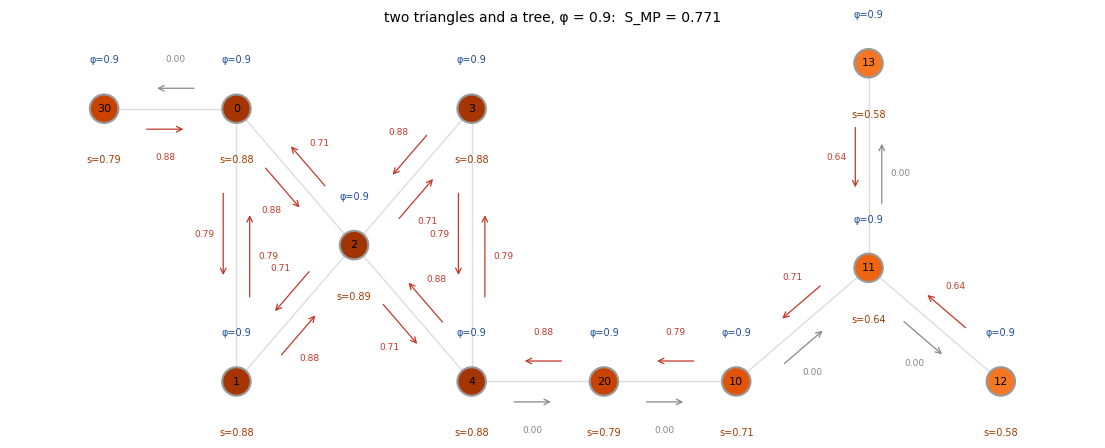

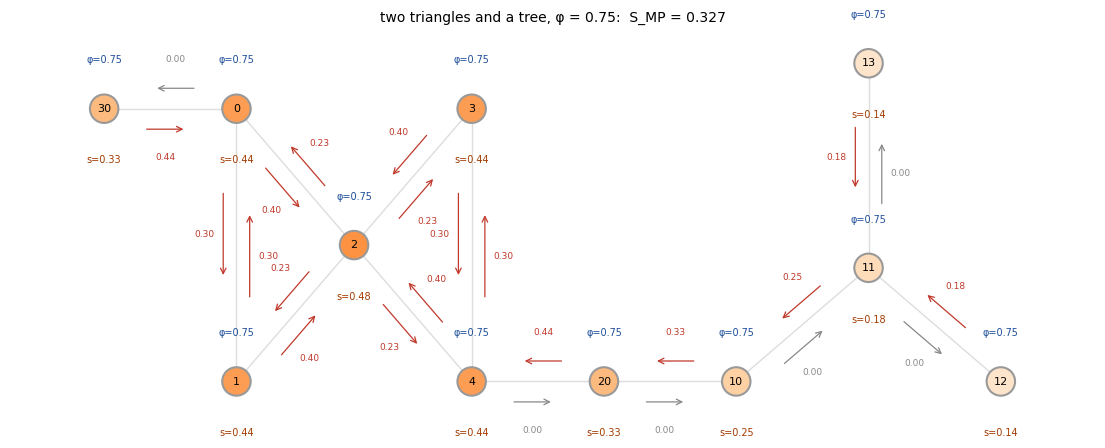

phi = 0.9: S_MP = 0.771, S_MC = 0.772


phi = 0.75: S_MP = 0.327, S_MC = 0.534


phi = 0.6: S_MP = 0.000, S_MC = 0.376


In [17]:
g_635 = nx.Graph([(0, 1), (1, 2), (2, 0), (2, 3), (3, 4), (4, 2),     # two triangles sharing node 2
                  (0, 30),                                              # a leaf on node 0
                  (4, 20), (20, 10), (10, 11), (11, 12), (11, 13)])     # a tree hanging from node 4 through node 20
pos_635 = {0: (-0.8, 0.6), 1: (-0.8, -0.6), 2: (0, 0), 3: (0.8, 0.6), 4: (0.8, -0.6), 30: (-1.7, 0.6),
           20: (1.7, -0.6), 10: (2.6, -0.6), 11: (3.5, -0.1), 12: (4.4, -0.6), 13: (3.5, 0.8)}
print(f"lambda_max = {lambda_max(matrice_G(g_635)[0]):.3f}")

for phi in [0.9, 0.75]:
    phi_n = {n: phi for n in g_635}
    S, s, t = message_passing(g_635, phi_n)[:3]
    fig, ax = plt.subplots(figsize=(14, 5))
    disegna_messaggi(ax, g_635, pos_635, phi_n, s, t, f"two triangles and a tree, φ = {phi}:  S_MP = {S:.3f}")
    plt.show()

rng_635 = np.random.default_rng(635)
for phi in [0.9, 0.75, 0.6]:
    S_mp = message_passing(g_635, phi)[0]
    S_mc = np.mean([mc_1run(g_635, phi, rng_635) for _ in range(20000)])
    print(f"phi = {phi}: S_MP = {S_mp:.3f}, S_MC = {S_mc:.3f}")


#### How the values come out

**Inside the two triangles.** The messages are between 0 and 1 and depend on how many routes leave the target node:
`t_{2→0} = 0.711` (node 0 has only node 1 ahead, apart from the leaf), `t_{0→2} = 0.878` (node 2 has three neighbours
ahead). The shared node 2 has four links leading to cycles: `s_2 = φ[1 − (1 − 0.711)^4] = 0.894`, the largest value.

**Messages away from the cycles are 0.** `t_{0→30} = 0`, `t_{4→20} = 0`, `t_{10→11} = 0`: from those nodes, without going
back, only leaves are left.

**Along the tree the value decreases by a factor φ at each step.** Every message towards the cycles reads only one
message: `t_{20→4} = 0.877`, `t_{10→20} = φ · t_{20→4} = 0.789`, `t_{11→10} = φ · 0.789 = 0.710`,
`t_{12→11} = φ · 0.710 = 0.639`. So `s_i` decreases with the distance from the triangles (0.789, 0.710, 0.639, 0.575):
a node far from the cycles needs more nodes to survive on its path.

**Message passing against Monte Carlo.** At `φ = 0.9` they agree (0.771 and 0.772). Closer to `1/λ = 0.69` they separate
(0.327 and 0.534 at `φ = 0.75`), and below it message passing gives 0 while Monte Carlo still finds a largest piece
(0.376 at `φ = 0.6`): on 11 nodes the difference of definition dominates.